# Stage 6 — XGBoost with a Chronological Split

Train one regressor per horizon using native NaN handling and the calendar-year protocol from Notebook 5. For each horizon, issue times whose labels cross a fitting boundary are purged. Early stopping on 2022 chooses the tree count, then a fresh model with that fixed count is refitted on permissible 2021–2022 rows and evaluated on 2023.

The comparison bar is read dynamically from `baseline_scores.csv`; no baseline metric is hard-coded in this notebook. Primary scores use the exact persistence mask, and secondary scores cover every observed target.

## Outputs

- `models/xgb_h{1..7}.json`
- `data/processed/xgb_scores.csv`
- `data/processed/xgb_scores_all_targets.csv`
- `data/processed/xgb_training_audit.csv`
- `data/processed/xgb_model_manifest.json`
- `figs/06_xgb_vs_baselines.png`


## 6.0 — Load sample, manifest, baseline scores

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

PROC_DIR = Path("data/processed")
MODEL_DIR = Path("models")
FIG_DIR = Path("figs")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_PATH = PROC_DIR / "supervised_sample.parquet"
FEATURE_MANIFEST_PATH = PROC_DIR / "feature_manifest.json"
SPLIT_MANIFEST_PATH = PROC_DIR / "split_manifest.json"
BASELINE_PATH = PROC_DIR / "baseline_scores.csv"

for path in (
    SAMPLE_PATH,
    FEATURE_MANIFEST_PATH,
    SPLIT_MANIFEST_PATH,
    BASELINE_PATH,
):
    assert path.exists(), f"Missing {path}"

df = (
    pd.read_parquet(SAMPLE_PATH)
    .sort_values(["time", "latitude", "longitude"])
    .reset_index(drop=True)
)
df["time"] = pd.to_datetime(df["time"])

manifest = json.loads(FEATURE_MANIFEST_PATH.read_text())
split_protocol = json.loads(SPLIT_MANIFEST_PATH.read_text())

HORIZONS = manifest["horizons"]
FEATURE_COLS = manifest["feature_cols"]
TARGET_COLS = manifest["target_cols"]

baselines = pd.read_csv(BASELINE_PATH)

if "evaluation_scope" not in baselines.columns:
    raise RuntimeError(
        "Baseline file is stale — rerun Notebook 5."
    )

baselines = baselines[
    baselines["evaluation_scope"]
    == "common_persistence_mask"
].copy()

baseline_best = (
    baselines.loc[
        baselines.groupby("horizon")["rmse"].idxmin()
    ]
    .set_index("horizon")
    .sort_index()
)

persistence = (
    baselines[baselines["method"] == "persistence"]
    .set_index("horizon")
    .sort_index()
)

print(f"Rows       : {len(df):,}")
print(f"Time range : {df.time.min().date()} → {df.time.max().date()}")
print(f"Features   : {len(FEATURE_COLS)}")
print(f"Horizons   : {HORIZONS}")

print("\nStrongest comparison baseline:")
for h, row in baseline_best.iterrows():
    print(
        f"  H+{h}: {row.method}, "
        f"RMSE={row.rmse:.4f}, R²={row.r2:.4f}, "
        f"N={int(row.n):,}"
    )

Rows       : 360,000
Time range : 2021-01-01 → 2023-12-30
Features   : 15
Horizons   : [1, 2, 3, 4, 5, 6, 7]

Strongest comparison baseline:
  H+1: persistence, RMSE=0.1037, R²=0.8497, N=50,166
  H+2: persistence, RMSE=0.1224, R²=0.7988, N=47,278
  H+3: persistence, RMSE=0.1332, R²=0.7542, N=45,124
  H+4: climatology, RMSE=0.1348, R²=0.7453, N=44,819
  H+5: climatology, RMSE=0.1346, R²=0.7383, N=44,218
  H+6: climatology, RMSE=0.1335, R²=0.7447, N=44,020
  H+7: climatology, RMSE=0.1339, R²=0.7528, N=44,010


## 6.1 — Calendar-year split and horizon purge

Read the exact split dates from `split_manifest.json`: train on 2021, validate on 2022, test on 2023, and refit on permissible 2021–2022 rows. For horizon `h`, remove issue times whose label date would extend beyond the end of the relevant fitting period.


In [2]:
TRAIN_START = pd.Timestamp(split_protocol["train_start"])
TRAIN_END = pd.Timestamp(split_protocol["train_end"])
VAL_START = pd.Timestamp(split_protocol["validation_start"])
VAL_END = pd.Timestamp(split_protocol["validation_end"])
TEST_START = pd.Timestamp(split_protocol["test_start"])
TEST_END = pd.Timestamp(split_protocol["test_end"])

train = df[df["time"].between(TRAIN_START, TRAIN_END)].copy()
val = df[df["time"].between(VAL_START, VAL_END)].copy()
test = df[df["time"].between(TEST_START, TEST_END)].copy()

reference = pd.concat(
    [train, val],
    ignore_index=True,
)

# A composite target at t+h includes t+h through t+h+2.
LABEL_EXTRA_DAYS = (
    2 if manifest.get("use_3day_target", False) else 0
)

print(
    f"train : {train.time.min().date()} → "
    f"{train.time.max().date()} ({len(train):,})"
)
print(
    f"val   : {val.time.min().date()} → "
    f"{val.time.max().date()} ({len(val):,})"
)
print(
    f"test  : {test.time.min().date()} → "
    f"{test.time.max().date()} ({len(test):,})"
)
print(
    f"refit : {reference.time.min().date()} → "
    f"{reference.time.max().date()} ({len(reference):,})"
)
print(f"Composite label extension: {LABEL_EXTRA_DAYS} days")

train : 2021-01-01 → 2021-12-31 (120,000)
val   : 2022-01-01 → 2022-12-31 (120,000)
test  : 2023-01-01 → 2023-12-30 (120,000)
refit : 2021-01-01 → 2022-12-31 (240,000)
Composite label extension: 0 days


## 6.2 — Tune, refit, and score one model per horizon

Use the common parameter set with a soft cap of 1,200 trees and `early_stopping_rounds=50`. Phase 1 selects the tree count from 2021 training and 2022 validation data. Phase 2 refits a new model with that fixed count on all permissible pre-test rows. Missing feature values remain as NaN; only rows with a missing target are excluded from fitting.

Report a primary score on the common persistence mask and a secondary operational score on all rows with an observed target.


In [3]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score

def score_arrays(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "rmse": float(
            np.sqrt(mean_squared_error(y_true, y_pred))
        ),
        "r2": float(r2_score(y_true, y_pred)),
        "n": int(len(y_true)),
    }

COMMON_PARAMS = {
    "max_depth": 6,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "missing": np.nan,
    "eval_metric": "rmse",
    "objective": "reg:squarederror",
    "tree_method": "hist",
    "n_jobs": -1,
    "random_state": 42,
    "verbosity": 0,
}

models = {}
xgb_rows_common = []
xgb_rows_all = []
training_audit = []

for h in HORIZONS:
    target_col = f"target_h{h}"
    label_offset = h + LABEL_EXTRA_DAYS

    # Purge issue times whose target would cross the period boundary.
    train_deadline = TRAIN_END - pd.Timedelta(
        days=label_offset
    )
    val_deadline = VAL_END - pd.Timedelta(
        days=label_offset
    )
    reference_deadline = VAL_END - pd.Timedelta(
        days=label_offset
    )

    train_h = train[
        (train["time"] <= train_deadline)
        & train[target_col].notna()
    ].copy()

    val_h = val[
        (val["time"] <= val_deadline)
        & val[target_col].notna()
    ].copy()

    reference_h = reference[
        (reference["time"] <= reference_deadline)
        & reference[target_col].notna()
    ].copy()

    if train_h.empty or val_h.empty or reference_h.empty:
        raise RuntimeError(
            f"Empty fitting split for H+{h}"
        )

    # Phase 1: choose the tree count using 2021/2022.
    tuning_model = xgb.XGBRegressor(
        n_estimators=1200,
        early_stopping_rounds=50,
        **COMMON_PARAMS,
    )

    tuning_model.fit(
        train_h[FEATURE_COLS],
        train_h[target_col],
        eval_set=[
            (
                val_h[FEATURE_COLS],
                val_h[target_col],
            )
        ],
        verbose=False,
    )

    best_rounds = int(tuning_model.best_iteration) + 1

    # Phase 2: refit that fixed tree count on all pre-test data.
    final_model = xgb.XGBRegressor(
        n_estimators=best_rounds,
        **COMMON_PARAMS,
    )

    final_model.fit(
        reference_h[FEATURE_COLS],
        reference_h[target_col],
        verbose=False,
    )

    models[h] = final_model

    # Operational score: every test row with an observed target.
    all_mask = test[target_col].notna()

    pred_all = final_model.predict(
        test.loc[all_mask, FEATURE_COLS]
    )

    score_all = score_arrays(
        test.loc[all_mask, target_col].to_numpy(),
        pred_all,
    )

    xgb_rows_all.append({
        "method": "xgboost",
        "horizon": h,
        "evaluation_scope": "all_observed_targets",
        "best_rounds": best_rounds,
        **score_all,
    })

    # Baseline comparison score: exact mask used by Notebook 5.
    common_mask = (
        test[target_col].notna()
        & test["log_chl_t0"].notna()
    )

    pred_common = final_model.predict(
        test.loc[common_mask, FEATURE_COLS]
    )

    score_common = score_arrays(
        test.loc[common_mask, target_col].to_numpy(),
        pred_common,
    )

    xgb_rows_common.append({
        "method": "xgboost",
        "horizon": h,
        "evaluation_scope": "common_persistence_mask",
        "best_rounds": best_rounds,
        **score_common,
    })

    training_audit.append({
        "horizon": h,
        "label_offset_days": label_offset,
        "best_rounds": best_rounds,
        "train_rows": len(train_h),
        "validation_rows": len(val_h),
        "refit_rows": len(reference_h),
        "common_test_rows": int(common_mask.sum()),
        "all_target_test_rows": int(all_mask.sum()),
        "train_max_label_time": (
            train_h["time"].max()
            + pd.Timedelta(days=label_offset)
        ),
        "validation_max_label_time": (
            val_h["time"].max()
            + pd.Timedelta(days=label_offset)
        ),
        "refit_max_label_time": (
            reference_h["time"].max()
            + pd.Timedelta(days=label_offset)
        ),
    })

    baseline = baseline_best.loc[h]

    delta_r2 = score_common["r2"] - baseline["r2"]
    delta_rmse_pct = (
        100
        * (baseline["rmse"] - score_common["rmse"])
        / baseline["rmse"]
    )

    print(
        f"H+{h}  rounds={best_rounds:3d}  "
        f"common RMSE={score_common['rmse']:.4f}, "
        f"R²={score_common['r2']:.4f}  |  "
        f"best baseline={baseline['method']} "
        f"RMSE={baseline['rmse']:.4f}, "
        f"R²={baseline['r2']:.4f}  |  "
        f"ΔRMSE={delta_rmse_pct:+.2f}%, "
        f"ΔR²={delta_r2:+.4f}  |  "
        f"all-target N={score_all['n']:,}"
    )

H+1  rounds=158  common RMSE=0.0968, R²=0.8691  |  best baseline=persistence RMSE=0.1037, R²=0.8497  |  ΔRMSE=+6.68%, ΔR²=+0.0194  |  all-target N=72,294
H+2  rounds=138  common RMSE=0.1118, R²=0.8321  |  best baseline=persistence RMSE=0.1224, R²=0.7988  |  ΔRMSE=+8.64%, ΔR²=+0.0332  |  all-target N=71,909
H+3  rounds=140  common RMSE=0.1184, R²=0.8057  |  best baseline=persistence RMSE=0.1332, R²=0.7542  |  ΔRMSE=+11.10%, ΔR²=+0.0515  |  all-target N=71,709
H+4  rounds=126  common RMSE=0.1223, R²=0.7901  |  best baseline=climatology RMSE=0.1348, R²=0.7453  |  ΔRMSE=+9.22%, ΔR²=+0.0448  |  all-target N=71,255
H+5  rounds=133  common RMSE=0.1281, R²=0.7630  |  best baseline=climatology RMSE=0.1346, R²=0.7383  |  ΔRMSE=+4.83%, ΔR²=+0.0247  |  all-target N=70,997
H+6  rounds=144  common RMSE=0.1325, R²=0.7486  |  best baseline=climatology RMSE=0.1335, R²=0.7447  |  ΔRMSE=+0.75%, ΔR²=+0.0038  |  all-target N=70,749
H+7  rounds=148  common RMSE=0.1336, R²=0.7539  |  best baseline=climatolog

## 6.3 — Build comparison tables, plots, and training audit

Place only common-mask XGBoost scores beside persistence and climatology. Keep the broader all-target scores separate, and record the selected tree count and latest fitted label date for every horizon.


In [4]:
xgb_scores = (
    pd.DataFrame(xgb_rows_common)
    .sort_values("horizon")
    .reset_index(drop=True)
)

xgb_scores_all = (
    pd.DataFrame(xgb_rows_all)
    .sort_values("horizon")
    .reset_index(drop=True)
)

training_audit_df = (
    pd.DataFrame(training_audit)
    .sort_values("horizon")
    .reset_index(drop=True)
)

# Only common-mask XGBoost scores belong beside the baselines.
all_scores = pd.concat(
    [
        baselines[
            [
                "method",
                "horizon",
                "evaluation_scope",
                "rmse",
                "r2",
                "n",
            ]
        ],
        xgb_scores[
            [
                "method",
                "horizon",
                "evaluation_scope",
                "rmse",
                "r2",
                "n",
            ]
        ],
    ],
    ignore_index=True,
)

wide = all_scores.pivot(
    index="horizon",
    columns="method",
    values=["rmse", "r2", "n"],
)
wide.columns = [
    f"{method}_{metric}"
    for metric, method in wide.columns
]

print("Common-mask comparison:")
print(wide.round(4).to_string())

print("\nOperational all-observed-target score:")
print(
    xgb_scores_all[
        ["horizon", "rmse", "r2", "n", "best_rounds"]
    ].round(4).to_string(index=False)
)

print("\nTraining audit:")
print(training_audit_df.to_string(index=False))

Common-mask comparison:
         climatology_rmse  persistence_rmse  xgboost_rmse  climatology_r2  persistence_r2  xgboost_r2  climatology_n  persistence_n  xgboost_n
horizon                                                                                                                                       
1                  0.1350            0.1037        0.0968          0.7454          0.8497      0.8691        50166.0        50166.0    50166.0
2                  0.1359            0.1224        0.1118          0.7520          0.7988      0.8321        47278.0        47278.0    47278.0
3                  0.1347            0.1332        0.1184          0.7485          0.7542      0.8057        45124.0        45124.0    45124.0
4                  0.1348            0.1375        0.1223          0.7453          0.7347      0.7901        44819.0        44819.0    44819.0
5                  0.1346            0.1467        0.1281          0.7383          0.6893      0.7630        44218.0  

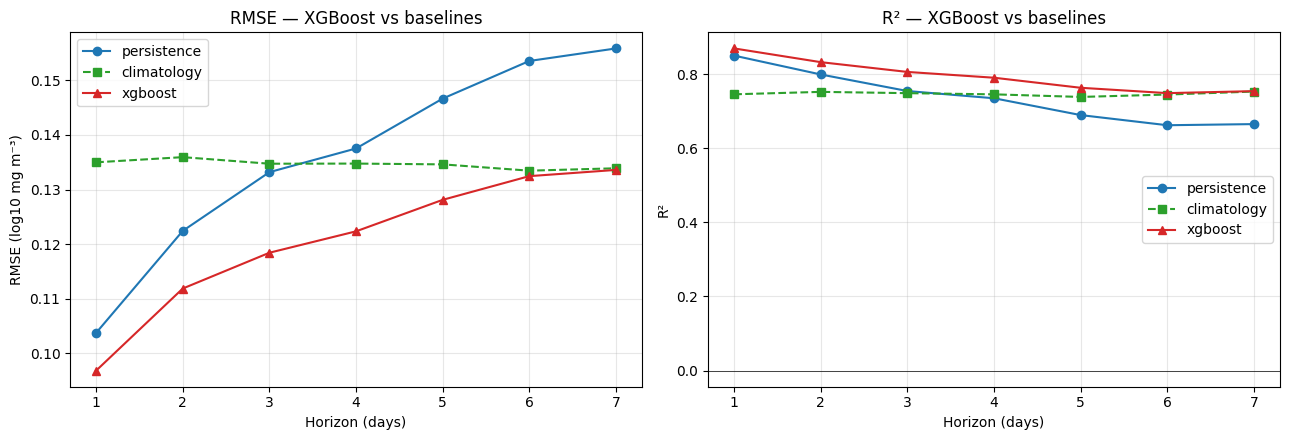

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

styles = [
    ("persistence", "o", "#1f77b4", "-"),
    ("climatology", "s", "#2ca02c", "--"),
    ("xgboost",     "^", "#d62728", "-"),
]
for method, marker, color, ls in styles:
    sub = all_scores[all_scores.method == method].sort_values("horizon")
    axes[0].plot(sub.horizon, sub.rmse, marker=marker, color=color, linestyle=ls, label=method)
    axes[1].plot(sub.horizon, sub.r2,   marker=marker, color=color, linestyle=ls, label=method)

axes[0].set_xlabel("Horizon (days)"); axes[0].set_ylabel("RMSE (log10 mg m⁻³)")
axes[0].set_title("RMSE — XGBoost vs baselines"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_xlabel("Horizon (days)"); axes[1].set_ylabel("R²")
axes[1].set_title("R² — XGBoost vs baselines");   axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].axhline(0, color="k", linewidth=0.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "06_xgb_vs_baselines.png", dpi=150)
plt.show()

---
## Validation Gate 6

The gate checks the 360,000-row sample, exact ordered calendar-year splits, horizon-aware label purges, one model per horizon, matched baseline/model comparison counts, and broader all-target coverage. It also requires plausible H+1 skill, improvement over persistence from H+3 through H+7, a match or win against the strongest baseline at every horizon within the declared 0.5% RMSE tolerance, and lower overall skill at H+7 than H+1.

Models and score artifacts are saved only after every check passes.


In [6]:
results = {}

results["360,000-row sample loaded"] = (
    len(df) == 360_000
)

results["train is exactly 2021"] = (
    set(train["time"].dt.year.unique()) == {2021}
)
results["validation is exactly 2022"] = (
    set(val["time"].dt.year.unique()) == {2022}
)
results["test is exactly 2023"] = (
    set(test["time"].dt.year.unique()) == {2023}
)

results["splits are ordered and non-overlapping"] = (
    train.time.max() < val.time.min()
    and val.time.max() < test.time.min()
)

# No fitted label may cross into the next period.
results["training labels do not cross into validation"] = bool(
    (
        pd.to_datetime(
            training_audit_df["train_max_label_time"]
        )
        <= TRAIN_END
    ).all()
)

results["validation labels do not cross into test"] = bool(
    (
        pd.to_datetime(
            training_audit_df["validation_max_label_time"]
        )
        <= VAL_END
    ).all()
)

results["refit labels do not cross into test"] = bool(
    (
        pd.to_datetime(
            training_audit_df["refit_max_label_time"]
        )
        <= VAL_END
    ).all()
)

results["one model exists for every horizon"] = (
    set(models) == set(HORIZONS)
)

xgb_by_h = xgb_scores.set_index("horizon")
xgb_all_by_h = xgb_scores_all.set_index("horizon")

# Verify exact equality with Notebook 5's persistence mask.
baseline_n = (
    baselines[baselines["method"] == "persistence"]
    .set_index("horizon")["n"]
    .astype(int)
)

results["XGBoost and baselines use identical comparison N"] = all(
    int(xgb_by_h.loc[h, "n"]) == int(baseline_n.loc[h])
    for h in HORIZONS
)

results["all-target score covers at least the common mask"] = all(
    int(xgb_all_by_h.loc[h, "n"])
    >= int(xgb_by_h.loc[h, "n"])
    for h in HORIZONS
)

h1_r2 = float(xgb_by_h.loc[1, "r2"])
results["H+1 R² is plausible"] = (
    0.6 <= h1_r2 <= 0.95
)

# Retain the original project requirement.
results["beats persistence at H+3 through H+7"] = all(
    xgb_by_h.loc[h, "rmse"]
    < persistence.loc[h, "rmse"]
    for h in [3, 4, 5, 6, 7]
)

# Sampling noise can produce extremely small reversals. Within 0.5%
# RMSE is reported as a statistical/practical tie, not as a win.
STRONGEST_BASELINE_TOLERANCE = 0.005

results["matches/beats strongest baseline within 0.5%"] = all(
    xgb_by_h.loc[h, "rmse"]
    <= baseline_best.loc[h, "rmse"]
       * (1 + STRONGEST_BASELINE_TOLERANCE)
    for h in HORIZONS
)

r2_values = xgb_by_h.sort_index()["r2"].to_numpy()
results["H+1 R² exceeds H+7 R² overall"] = (
    r2_values[0] > r2_values[-1]
)

for name, ok in results.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print("\nDelta against the strongest baseline:")
for h in HORIZONS:
    model_row = xgb_by_h.loc[h]
    baseline_row = baseline_best.loc[h]

    delta_r2 = model_row["r2"] - baseline_row["r2"]
    delta_rmse_pct = (
        100
        * (baseline_row["rmse"] - model_row["rmse"])
        / baseline_row["rmse"]
    )

    if delta_rmse_pct > 0:
        status = "BEAT"
    elif delta_rmse_pct >= -0.5:
        status = "TIE"
    else:
        status = "BELOW"

    print(
        f"  H+{h}: {status:5s} vs {baseline_row['method']}  "
        f"ΔRMSE={delta_rmse_pct:+.2f}%  "
        f"ΔR²={delta_r2:+.4f}"
    )

failed = [
    name
    for name, ok in results.items()
    if not ok
]

if failed:
    raise RuntimeError(
        "Validation Gate 6 failed:\n- "
        + "\n- ".join(failed)
    )

# Persist only after the corrected gate passes.
for h, model in models.items():
    model.save_model(
        MODEL_DIR / f"xgb_h{h}.json"
    )

xgb_scores.to_csv(
    PROC_DIR / "xgb_scores.csv",
    index=False,
)
xgb_scores_all.to_csv(
    PROC_DIR / "xgb_scores_all_targets.csv",
    index=False,
)
training_audit_df.to_csv(
    PROC_DIR / "xgb_training_audit.csv",
    index=False,
)

model_manifest = {
    "protocol": split_protocol["model_policy"],
    "feature_manifest": str(FEATURE_MANIFEST_PATH),
    "split_manifest": str(SPLIT_MANIFEST_PATH),
    "primary_evaluation_scope": "common_persistence_mask",
    "secondary_evaluation_scope": "all_observed_targets",
    "strongest_baseline_tolerance_fraction": (
        STRONGEST_BASELINE_TOLERANCE
    ),
    "best_rounds": {
        str(int(row["horizon"])): int(row["best_rounds"])
        for _, row in training_audit_df.iterrows()
    },
}

(PROC_DIR / "xgb_model_manifest.json").write_text(
    json.dumps(model_manifest, indent=2)
)

print("\nGate 6 PASSED.")
print("Saved seven refitted models.")
print("Saved common-mask, all-target, and training-audit scores.")

PASS  360,000-row sample loaded
PASS  train is exactly 2021
PASS  validation is exactly 2022
PASS  test is exactly 2023
PASS  splits are ordered and non-overlapping
PASS  training labels do not cross into validation
PASS  validation labels do not cross into test
PASS  refit labels do not cross into test
PASS  one model exists for every horizon
PASS  XGBoost and baselines use identical comparison N
PASS  all-target score covers at least the common mask
PASS  H+1 R² is plausible
PASS  beats persistence at H+3 through H+7
PASS  matches/beats strongest baseline within 0.5%
PASS  H+1 R² exceeds H+7 R² overall

Delta against the strongest baseline:
  H+1: BEAT  vs persistence  ΔRMSE=+6.68%  ΔR²=+0.0194
  H+2: BEAT  vs persistence  ΔRMSE=+8.64%  ΔR²=+0.0332
  H+3: BEAT  vs persistence  ΔRMSE=+11.10%  ΔR²=+0.0515
  H+4: BEAT  vs climatology  ΔRMSE=+9.22%  ΔR²=+0.0448
  H+5: BEAT  vs climatology  ΔRMSE=+4.83%  ΔR²=+0.0247
  H+6: BEAT  vs climatology  ΔRMSE=+0.75%  ΔR²=+0.0038
  H+7: BEAT  vs cl

---
## Result and next step

This notebook establishes the leakage-safe v1 model and its baseline comparison. Notebook 7 diagnoses what it learned and where it fails. Notebook 8 then tests whether physical and optical feature groups add reproducible value under the same split and evaluation masks.

## Next: `07-Interpretability.ipynb`

Compute SHAP summaries, spatial and seasonal error diagnostics, residual checks, and an optional interactive map viewer.
